# Lab 1 · Dal dataset al modello equo
**AI 4 Security · Parte 1 · Fondamenti** — Versione studente

In questo laboratorio percorriamo l'intera catena vista nei moduli 1-4, sul caso di studio delle **richieste di prestito**:

| Fase | Cosa fai | Moduli |
|---|---|---|
| 1 · Esplora | diagnosi del dataset, valori mancanti, scoperta del bias con `groupby` | 01 · 02 |
| 2 · Addestra | `train_test_split`, albero di decisione, `max_depth` e overfitting | 03 |
| 3 · Valuta | matrice di confusione, precision e recall, casi limite, metriche per zona | 04 |

**Consegna finale:** una tabella con accuratezza e recall per zona, il valore di `max_depth` scelto e due righe di commento: il modello è "giusto" ma ingiusto? Cosa cambieresti nei dati?

**Come lavorare:** esegui le celle in ordine con `Shift+Invio`. Le celle marcate `TODO` vanno completate; le celle **Controllo** ti dicono se sei sulla strada giusta.

## 0 · Preparazione

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)
SEED = 42
print("Ambiente pronto")

Ambiente pronto


Il modulo `dati_prestiti` usato nelle slide qui è sostituito da una funzione `carica_dati()` che **genera** un dataset sintetico realistico.
Esegui la cella senza modificarla: non serve leggerne il contenuto per svolgere il laboratorio (anzi, prova a scoprire il bias dai dati, non dal codice).

In [16]:
# @title Generazione del dataset (eseguire senza modificare)

def carica_dati(n=2000, seed=42):
    """Genera il dataset sintetico delle richieste di prestito."""
    rng = np.random.default_rng(seed)
    zona = rng.choice(["A", "B"], size=n, p=[0.6, 0.4])
    eta = np.clip(rng.normal(41, 11, n), 20, 70).round().astype(int)
    anni_lavoro = np.clip(eta - 22 - rng.integers(0, 12, n), 0, None).astype(float)
    reddito = np.where(zona == "A", rng.normal(38000, 9000, n), rng.normal(28000, 8000, n))
    reddito = np.clip(reddito, 9000, None).round(-2)
    importo = np.clip(rng.lognormal(9.4, 0.5, n), 1000, 60000).round(-2)
    rata_mensile = importo / 60
    rapporto = (rata_mensile / (reddito / 12)).round(3)
    insoluti = np.clip(rng.poisson(np.where(zona == "A", 0.3, 0.5)), 0, 3)
    # decisione storica: include una penalità per la zona B (il bias che vogliamo scoprire)
    score = (0.9 - 7.5 * rapporto - 0.9 * insoluti + 0.00005 * (reddito - 32000)
             + 0.02 * anni_lavoro - 0.6 * (zona == "B"))
    p = 1 / (1 + np.exp(-2.2 * score))
    approvato = (rng.random(n) < p).astype(int)
    anni_lavoro[rng.random(n) < 0.08] = np.nan
    return pd.DataFrame({"età": eta, "reddito": reddito, "anni_lavoro": anni_lavoro,
                         "importo_richiesto": importo, "rapporto_rata_reddito": rapporto,
                         "insoluti_passati": insoluti, "zona": zona, "approvato": approvato})

print('Funzione carica_dati() pronta')

Funzione carica_dati() pronta


---
## Fase 1 · Esplora: guardare i dati prima del modello

Ogni riga è una richiesta di prestito. Le colonne:

| colonna | significato |
|---|---|
| `età`, `reddito`, `anni_lavoro` | caratteristiche di chi chiede |
| `importo_richiesto`, `rapporto_rata_reddito` | quanto chiede e quanto pesa la rata sul reddito mensile |
| `insoluti_passati` | quante rate non pagate in passato |
| `zona` | zona di residenza A / B: **attributo sensibile** |
| `approvato` | **l'etichetta**: decisione storica, 1 = concesso, 0 = negato |

In [17]:
df = carica_dati()
df.head()

,età,reddito,anni_lavoro,importo_richiesto,rapporto_rata_reddito,insoluti_passati,zona,approvato
0,30,21900.0,8.0,10400.0,0.095,0,B,0
1,51,47500.0,21.0,8600.0,0.036,0,A,1
2,28,16800.0,1.0,18900.0,0.225,0,B,0
3,38,34500.0,5.0,5900.0,0.034,0,B,1
4,35,53600.0,11.0,7400.0,0.028,0,A,1


### 1.1 · La prima diagnosi: `.shape`, `.info()`, `.describe()`

In [28]:
# TODO: stampa dimensioni, tipi e statistiche di base del DataFrame
print("Righe, colonne:", df.shape)
df.info()
df.describe().round(2)

Righe, colonne: (2000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   età                    2000 non-null   int64  
 1   reddito                2000 non-null   float64
 2   anni_lavoro            1841 non-null   float64
 3   importo_richiesto      2000 non-null   float64
 4   rapporto_rata_reddito  2000 non-null   float64
 5   insoluti_passati       2000 non-null   int64  
 6   zona                   2000 non-null   object 
 7   approvato              2000 non-null   int64  
 8   rata_mensile           2000 non-null   float64
dtypes: float64(5), int64(3), object(1)
memory usage: 140.8+ KB


,età,reddito,anni_lavoro,importo_richiesto,rapporto_rata_reddito,insoluti_passati,approvato,rata_mensile
count,2000.00,2000.00,1841.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,41.30,34202.25,14.43,13518.55,0.09,0.36,0.54,225.28
std,10.71,10035.83,10.26,7469.11,0.06,0.60,0.50,124.49
min,20.00,9000.00,0.00,2400.00,0.01,0.00,0.00,39.22
25%,34.00,27275.00,6.00,8400.00,0.05,0.00,0.00,140.86
50%,41.00,34000.00,14.00,11700.00,0.07,0.00,1.00,195.00
75%,48.25,40700.00,22.00,16800.00,0.11,1.00,1.00,278.78
max,70.00,67200.00,48.00,60000.00,0.43,3.00,1.00,1000.83


### 1.2 · Valori mancanti
Quante celle vuote ci sono per colonna? Quale colonna è coinvolta?

In [19]:
# TODO: conta i valori mancanti per colonna e salva il risultato in `mancanti`
mancanti = df.isna().sum()
print(mancanti)

età                        0
reddito                    0
anni_lavoro              159
importo_richiesto          0
rapporto_rata_reddito      0
insoluti_passati           0
zona                       0
approvato                  0
dtype: int64


In [20]:
# Controllo
assert mancanti["anni_lavoro"] > 0, "Dovresti trovare dei valori mancanti in anni_lavoro"
print("OK: trovati", int(mancanti["anni_lavoro"]), "valori mancanti in anni_lavoro")

OK: trovati 159 valori mancanti in anni_lavoro


> **Attenzione.** Non riempiamo ancora i mancanti: la **regola d'oro** del modulo 1 dice che ogni parametro di preprocessing (qui la mediana)
> va calcolato **solo sul training set**. Lo faremo nella fase 2, dopo lo split.

### 1.3 · Il gesto che rivela il bias
Il tasso storico di approvazione cambia a seconda della zona?

In [21]:
# TODO: calcola la quota di approvati per zona con groupby e salvala in `tasso_zona`
tasso_zona = df.groupby("zona")["approvato"].mean()
print(tasso_zona)

zona
A    0.744
B    0.246
Name: approvato, dtype: float64


In [22]:
# Controllo
assert set(tasso_zona.index) == {"A", "B"}
print("OK. Divario A - B:", round(tasso_zona["A"] - tasso_zona["B"], 3))

OK. Divario A - B: 0.498


Il divario potrebbe avere una spiegazione "legittima": magari in zona B i redditi sono più bassi. Verifichiamolo confrontando solo le **richieste solide**:
reddito superiore a 30.000 euro e nessun insoluto.

In [23]:
# TODO: filtra le richieste con reddito > 30000 e insoluti_passati == 0,
#       poi calcola di nuovo il tasso di approvazione per zona
solide = df[(df["reddito"] > 30000) & (df["insoluti_passati"] == 0)]
tasso_zona_solide = solide.groupby("zona")["approvato"].mean()
print(tasso_zona_solide)

#quindi notiamo che il divario tra le zone A e B si riduce, ma non scompare del tutto. Dunque, anche se il modello è più equo, non è ancora completamente equo. Questo ci fa capire che il bias non è solo dovuto a queste due variabili, ma anche ad altre variabili che influenzano la decisione di approvazione del prestito.

zona
A    0.891
B    0.524
Name: approvato, dtype: float64


### 1.4 · Esercizi di esplorazione

**a)** Crea la colonna `rata_mensile` (euro al mese) a partire da `rapporto_rata_reddito` e `reddito` (annuo).

In [24]:
# TODO: rata_mensile = rapporto_rata_reddito * reddito mensile
df["rata_mensile"] = df["rapporto_rata_reddito"] * (df["reddito"] / 12)
print(df[["rapporto_rata_reddito", "reddito", "rata_mensile"]].head())

   rapporto_rata_reddito  reddito  rata_mensile
0                  0.095  21900.0       173.375
1                  0.036  47500.0       142.500
2                  0.225  16800.0       315.000
3                  0.034  34500.0        97.750
4                  0.028  53600.0       125.067


**b)** Confronta il reddito medio per zona. **c)** Disegna l'istogramma della rata mensile separato per esito (approvato / negato).

zona
A    38324.435
B    28082.981
Name: reddito, dtype: float64


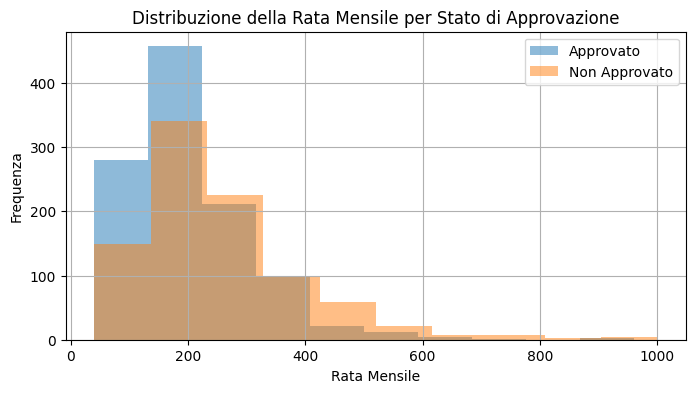

In [25]:
# TODO b) reddito medio per zona
reddito_zona = df.groupby("zona")["reddito"].mean()
print(reddito_zona)
# TODO c) istogramma di rata_mensile per approvato == 1 e approvato == 0 (due colori, alpha=0.5)
df[df["approvato"] == 1]["rata_mensile"].hist(alpha=0.5, label="Approvato")
df[df["approvato"] == 0]["rata_mensile"].hist(alpha=0.5, label="Non Approvato")
plt.xlabel("Rata Mensile")
plt.ylabel("Frequenza")
plt.title("Distribuzione della Rata Mensile per Stato di Approvazione")
plt.legend()
plt.show()

**Domanda di riflessione (scrivi la risposta qui sotto):** il reddito è diverso fra le zone. Se togliamo la colonna `zona` dal modello,
il reddito potrebbe "raccontare" la zona lo stesso? Come si chiama questo fenomeno?

*Risposta:* 

Se eliminiamo la zona dal modello, non servurebbe a niente, bisognerebbe creare una feature che renda dipendente il modello da quella feature. Deve essere piu sensibile, richiedere un finanziamento al sud è diverso rispetto a richiederlo a nord. Oppuyre un altra soluzione sarebbe dividere il dataset in base alla zona. Fare ub dataset zona A e un dataset zona B.

---
## Fase 2 · Addestra: il primo classificatore

Scegliamo le feature **senza la zona**, di proposito: nella fase 3 vedremo se questo basta a rendere il modello equo.

In [26]:
feature = ["età", "reddito", "anni_lavoro", "importo_richiesto",
           "rapporto_rata_reddito", "insoluti_passati"]
X = df[feature]
y = df["approvato"]
print(X.shape, y.mean().round(3))

(2000, 6) 0.544


### 2.1 · Split stratificato e riproducibile (75% training, 25% test)

In [29]:
# TODO: usa train_test_split con test_size=0.25, random_state=SEED e stratify=y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)


In [30]:
# Controllo
assert len(X_test) == 500 and abs(y_train.mean() - y_test.mean()) < 0.01
print("OK: split corretto e stratificato")

OK: split corretto e stratificato


### 2.2 · Regola d'oro: la mediana si calcola sul training e si applica al test

In [33]:
# TODO: crea un SimpleImputer(strategy="median"), fallo imparare (fit) solo su X_train,
#       poi trasforma sia X_train sia X_test
imputer = SimpleImputer(strategy="median")
X_train_i = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test_i = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

In [34]:
# Controllo
assert X_train_i.isna().sum().sum() == 0 and X_test_i.isna().sum().sum() == 0
print("OK: nessun valore mancante nei dati del modello")

OK: nessun valore mancante nei dati del modello


### 2.3 · Un albero di decisione: `fit` poi `predict`

In [ ]:
# TODO: albero con max_depth=3 e random_state=SEED; fit sul training, predict sul test
modello = DecisionTreeClassifier(max_depth=3, random_state=SEED) #max_depth=3 per evitare overfitting e random_state=SEED per riproducibilità
modello.fit(X_train_i, y_train)
y_pred = modello.predict(X_test_i)

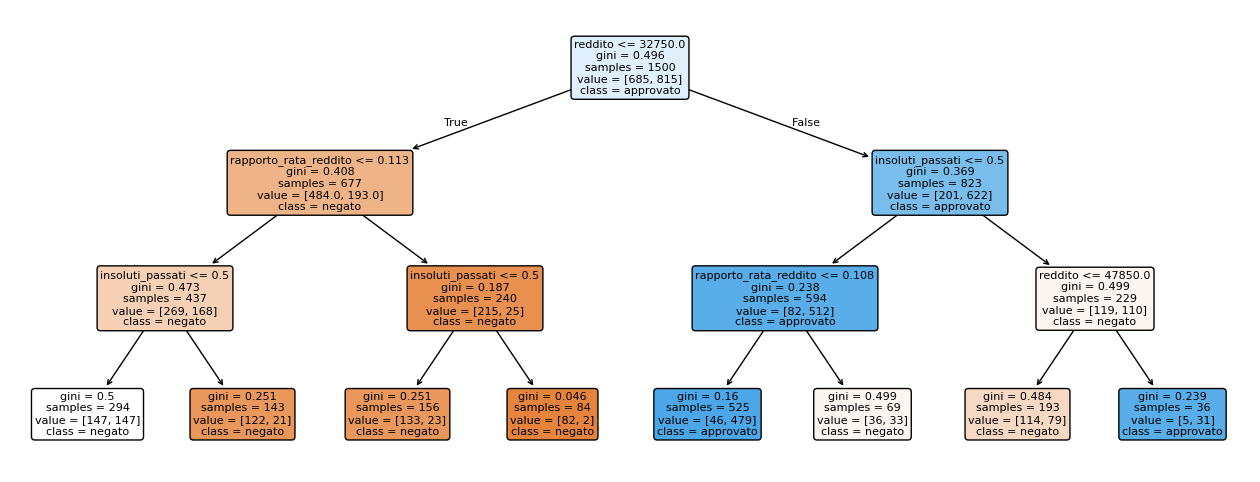

In [36]:
plt.figure(figsize=(16, 6))
plot_tree(modello, feature_names=feature, class_names=["negato", "approvato"],
          filled=True, rounded=True, fontsize=8)
plt.show()

**Domanda:** quali feature usa l'albero nelle prime domande? Ti sembrano ragionevoli?

*Risposta:* 
le prime feature usate dall albero decisionale sono 

### 2.4 · Overfitting dal vivo: varia `max_depth`

In [ ]:
# TODO: per ogni d in [1, 2, 3, 5, 8, 10, 15, None] addestra un albero e salva
#       accuratezza su training e su test in una lista di dizionari, poi in un DataFrame `curve`
righe = []
for d in [1, 2, 3, 5, 8, 10, 15, None]:
    modello = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    modello.fit(X_train_i, y_train)
    train_acc = accuracy_score(y_train, modello.predict(X_train_i))
    test_acc = accuracy_score(y_test, modello.predict(X_test_i))
    righe.append({"max_depth": d, "train_acc": train_acc, "test_acc": test_acc})
curve = pd.DataFrame(righe)
print(curve)


   max_depth  train_acc  test_acc
0        1.0      0.737     0.724
1        2.0      0.743     0.700
2        3.0      0.763     0.694
3        5.0      0.813     0.780
4        8.0      0.873     0.746
5       10.0      0.922     0.738
6       15.0      0.992     0.720
7        NaN      1.000     0.720


**Domanda:** quale `max_depth` sceglieresti e perché?

*Risposta:* 
Non sono ancora sicuro, dovremmo agire su altre variabili

### 2.5 · Confronto con la regressione logistica

In [39]:
# TODO: pipeline StandardScaler + LogisticRegression, fit sul training e accuratezza sul test
logreg = make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED))
logreg.fit(X_train_i, y_train)
y_pred_logreg = logreg.predict(X_test_i)

### 2.6 · Una richiesta nuova: approvato o no?

In [40]:
modello = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(X_train_i, y_train)
y_pred = modello.predict(X_test_i)

nuova = pd.DataFrame([{"età": 35, "reddito": 42000, "anni_lavoro": 10,
                       "importo_richiesto": 9000, "rapporto_rata_reddito": 0.043,
                       "insoluti_passati": 0}])
prob = modello.predict_proba(nuova)[0][1]
print("Probabilità di approvazione:", round(prob, 2))

Probabilità di approvazione: 0.96


---
## Fase 3 · Valuta: quali errori, e verso chi

Da qui in avanti usiamo l'albero con `max_depth=5` (cella precedente).

### 3.1 · Matrice di confusione e report

In [ ]:
# TODO: calcola la matrice di confusione in `cm`, visualizzala e stampa il classification_report
cm = confusion_matrix(y_test, y_pred)


In [ ]:
# Controllo
assert cm.shape == (2, 2) and cm.sum() == len(y_test)
tn, fp, fn, tp = cm.ravel()
print(f"OK · TP={tp}  FP={fp}  FN={fn}  TN={tn}")

Nel nostro caso:
- un **falso positivo** concede un prestito che non andava concesso (rischio per la banca);
- un **falso negativo** nega il prestito a chi lo meritava (danno per la persona).

### 3.2 · Casi limite: dove il modello è incerto

In [ ]:
# TODO: calcola le probabilità di approvazione sul test (predict_proba, colonna 1)
#       e seleziona le richieste con probabilità fra 0.4 e 0.6
prob_test = ...
limite = ...

In un sistema reale questi casi andrebbero a **revisione umana** (human-in-the-loop).

### 3.3 · Metriche per gruppo

Scrivi la funzione `metriche_per_gruppo(g)` che, **sul test set**, restituisce per la zona `g` un dizionario con:
`n`, `accuratezza`, `precision`, `recall`, `tasso_approvazione` (quota di approvati **dal modello**).

In [ ]:
zona_test = df.loc[X_test.index, "zona"]

In [ ]:
def metriche_per_gruppo(g, y_vero=y_test, y_prev=y_pred, zona=zona_test):
    k = (zona == g).values          # maschera: righe del test appartenenti alla zona g
    yt, yp = y_vero[k], y_prev[k]
    # TODO: restituisci il dizionario richiesto
    return {"n": int(k.sum()),
            "accuratezza": ...,
            "precision": ...,
            "recall": ...,
            "tasso_approvazione": ...}

tabella = pd.DataFrame({g: metriche_per_gruppo(g) for g in ["A", "B"]}).T
tabella

In [ ]:
# Controllo
assert set(tabella.columns) >= {"accuratezza", "recall", "tasso_approvazione"}
assert abs(tabella["n"].sum() - len(y_test)) == 0
print("OK. Accuratezza complessiva:", round(accuracy_score(y_test, y_pred), 3))
tabella[["accuratezza", "recall", "tasso_approvazione"]].plot(kind="bar", rot=0, color=["#1F2328", "#0A0AB4", "#E3002B"],
                                                              title="Metriche per zona")
plt.ylim(0, 1); plt.show()

### 3.4 · Esperimenti sull'equità

**a)** Aggiungi `zona` alle feature (codificata come 0/1), riaddestra e rifai la tabella. Il divario di recall aumenta o diminuisce?

**b)** Togli anche `reddito` (il proxy). Cosa succede all'accuratezza e al divario?

In [ ]:
# TODO: scrivi una funzione esperimento(colonne, con_zona=False) che:
#   1) costruisce X con le colonne indicate (più zona_B = 1 se zona == "B", se richiesto)
#   2) usa gli STESSI indici di training e test (X_train.index, X_test.index)
#   3) imputa la mediana (fit sul training), addestra un albero max_depth=5
#   4) restituisce accuratezza, recall_A, recall_B e divario_recall
def esperimento(colonne, con_zona=False):
    ...

# confronto = pd.DataFrame({...}).T

**c) Per discutere:** si potrebbe abbassare la soglia di decisione solo per la zona B (ad esempio 0,4 invece di 0,5) per pareggiare il recall.
Quali vantaggi e quali rischi vedi? Chi dovrebbe prendere questa decisione?

*Risposta:* 

---
## Consegna

Completa la tabella e il commento, poi salva il notebook (File → Salva una copia in Drive).

| | Zona A | Zona B |
|---|---|---|
| Accuratezza | | |
| Recall | | |
| Tasso di approvazione | | |

**`max_depth` scelto:** 

**Commento (due righe):** il modello è "giusto" ma ingiusto? Cosa cambieresti nei dati?